In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

In [3]:


try:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")
except FileNotFoundError:
    df = pd.read_csv("/home/patel-krish/anaconda3/BrainyBeam/heart.csv")

df = df.drop_duplicates()
df = df.dropna(subset=["target"])

X = df.drop("target", axis=1)
y = df["target"].astype(int)

X = X.apply(pd.to_numeric, errors="coerce")

feature_names = X.columns.tolist()



In [4]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)



In [5]:


model = RandomForestClassifier(
    n_estimators=100,
    max_depth=8,
    random_state=42
)

model.fit(X_train, y_train)

predictions = model.predict(X_test)

print("Model Accuracy:", round(
    accuracy_score(y_test, predictions), 4
))

print("Model F1 Score:", round(
    f1_score(y_test, predictions, zero_division=0), 4
))


Model Accuracy: 0.7705
Model F1 Score: 0.7879


In [6]:

np.random.seed(42)

background_size = min(40, len(X_train))

background_indices = np.random.choice(
    len(X_train),
    size=background_size,
    replace=False
)

background_data = X_train[background_indices]


explain_count = min(10, len(X_test))

explain_data = X_test[:explain_count]
explain_labels = y_test.iloc[:explain_count].to_numpy()


In [7]:
def predict_probability(data):

    probabilities = model.predict_proba(data)

    # Probability of target = 1
    class_index = list(model.classes_).index(1)

    return probabilities[:, class_index]



In [8]:
baseline_prediction = np.mean(
    predict_probability(background_data)
)

print("\nBaseline Prediction:")
print(round(baseline_prediction, 4))



Baseline Prediction:
0.5885


In [9]:
def calculate_shapley_values(
    observation,
    background,
    number_of_permutations=30
):

    number_of_features = observation.shape[0]

    shap_values = np.zeros(number_of_features)

    for permutation_number in range(number_of_permutations):

        
        feature_order = np.random.permutation(
            number_of_features
        )

        coalition = []

        previous_prediction = np.mean(
            predict_probability(background)
        )

        for feature_index in feature_order:

            coalition.append(feature_index)

           
            hybrid_data = background.copy()

            hybrid_data[:, coalition] = observation[
                coalition
            ]

            current_prediction = np.mean(
                predict_probability(hybrid_data)
            )

            contribution = (
                current_prediction - previous_prediction
            )

            shap_values[feature_index] += contribution

            previous_prediction = current_prediction

    shap_values /= number_of_permutations

    return shap_values



In [10]:

number_of_permutations = 30

all_shap_values = []

for i in range(explain_count):

    values = calculate_shapley_values(
        observation=explain_data[i],
        background=background_data,
        number_of_permutations=number_of_permutations
    )

    all_shap_values.append(values)

    print(
        f"Calculated SHAP values for observation {i + 1}"
    )

all_shap_values = np.array(all_shap_values)


Calculated SHAP values for observation 1
Calculated SHAP values for observation 2
Calculated SHAP values for observation 3
Calculated SHAP values for observation 4
Calculated SHAP values for observation 5
Calculated SHAP values for observation 6
Calculated SHAP values for observation 7
Calculated SHAP values for observation 8
Calculated SHAP values for observation 9
Calculated SHAP values for observation 10


In [11]:

shap_df = pd.DataFrame(
    all_shap_values,
    columns=feature_names
)

print("\nSHAP VALUES FOR EXPLAINED OBSERVATIONS")
print(shap_df.round(4))



SHAP VALUES FOR EXPLAINED OBSERVATIONS
      age     sex      cp  trestbps    chol     fbs  restecg  thalach   exang  \
0 -0.0089  0.0396 -0.1786   -0.0133 -0.0224 -0.0005   0.0054  -0.0204 -0.1161   
1 -0.0491 -0.0496  0.1371   -0.0095 -0.0581 -0.0020   0.0033   0.0339  0.0267   
2 -0.0089 -0.0283 -0.1211    0.0075  0.0047 -0.0005  -0.0087  -0.0809 -0.0529   
3  0.0075 -0.0451  0.1311   -0.0066  0.0375 -0.0009  -0.0018   0.0253  0.0324   
4 -0.0377  0.0722 -0.0317    0.0095 -0.0241  0.0014  -0.0106   0.0517  0.0579   
5 -0.0398 -0.0324 -0.1203    0.0008 -0.0027 -0.0003  -0.0003  -0.1077 -0.0778   
6  0.0415 -0.0325  0.1027    0.0124  0.0135 -0.0004  -0.0075   0.0804  0.0235   
7  0.0215 -0.0243 -0.1205   -0.0171  0.0420 -0.0013   0.0039  -0.0923 -0.0711   
8  0.0145  0.0453  0.1142    0.0070  0.0007  0.0002  -0.0019   0.0807 -0.0355   
9 -0.0778 -0.0470  0.1207   -0.0097  0.0029  0.0000   0.0167  -0.0008  0.0256   

   oldpeak   slope      ca    thal  
0  -0.0230 -0.0361  0.0395 -0.0

In [12]:


actual_probabilities = predict_probability(
    explain_data
)

reconstructed_probabilities = (
    baseline_prediction + all_shap_values.sum(axis=1)
)

verification_df = pd.DataFrame({
    "Observation": np.arange(1, explain_count + 1),
    "Actual Probability": actual_probabilities,
    "Baseline + SHAP": reconstructed_probabilities,
    "Difference": (
        actual_probabilities - reconstructed_probabilities
    )
})

print("\nPREDICTION RECONSTRUCTION CHECK")
print(verification_df.round(4).to_string(index=False))



PREDICTION RECONSTRUCTION CHECK
 Observation  Actual Probability  Baseline + SHAP  Difference
           1              0.1600           0.1600         0.0
           2              0.6571           0.6571         0.0
           3              0.0350           0.0350         0.0
           4              0.7617           0.7617         0.0
           5              0.8939           0.8939         0.0
           6              0.0400           0.0400        -0.0
           7              0.8481           0.8481         0.0
           8              0.1450           0.1450        -0.0
           9              0.9583           0.9583         0.0
          10              0.4092           0.4092         0.0


In [13]:


mean_absolute_shap = np.mean(
    np.abs(all_shap_values),
    axis=0
)

mean_shap = np.mean(
    all_shap_values,
    axis=0
)

shap_std = np.std(
    all_shap_values,
    axis=0
)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": mean_absolute_shap,
    "Mean SHAP": mean_shap,
    "Contribution Std": shap_std
})

importance_df = importance_df.sort_values(
    "Mean Absolute SHAP",
    ascending=False
).reset_index(drop=True)

print("\nFEATURE CONTRIBUTION ANALYSIS")
print(importance_df.round(4).to_string(index=False))

shap_df.to_csv(
    "manual_shap_values.csv",
    index=False
)

importance_df.to_csv(
    "manual_shap_feature_importance.csv",
    index=False
)




FEATURE CONTRIBUTION ANALYSIS
 Feature  Mean Absolute SHAP  Mean SHAP  Contribution Std
      cp              0.1178     0.0034            0.1227
      ca              0.0695     0.0110            0.0728
    thal              0.0593    -0.0113            0.0631
 thalach              0.0574    -0.0030            0.0667
 oldpeak              0.0573    -0.0415            0.0542
   exang              0.0520    -0.0187            0.0561
     sex              0.0416    -0.0102            0.0424
     age              0.0307    -0.0137            0.0349
    chol              0.0209    -0.0006            0.0280
   slope              0.0187    -0.0106            0.0179
trestbps              0.0094    -0.0019            0.0101
 restecg              0.0060    -0.0001            0.0077
     fbs              0.0008    -0.0004            0.0009


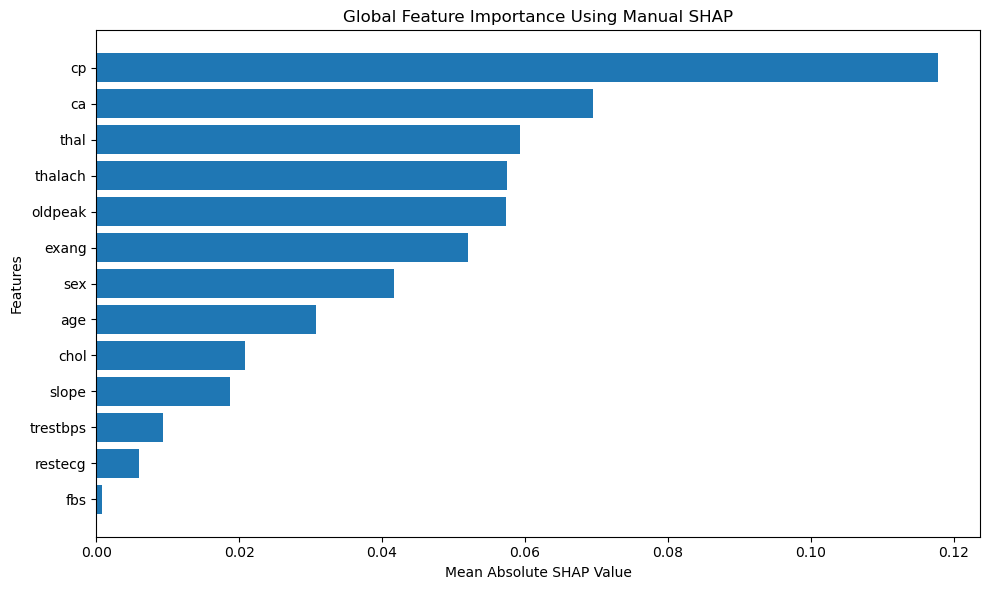

In [14]:

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Mean Absolute SHAP"]
)

plt.gca().invert_yaxis()

plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Features")
plt.title("Global Feature Importance Using Manual SHAP")

plt.tight_layout()
plt.show()



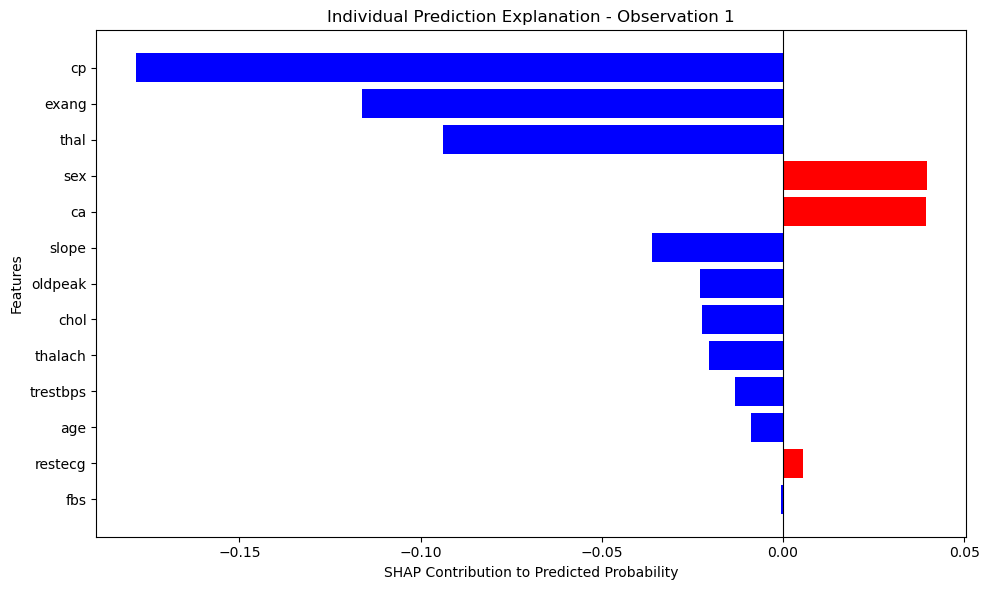

In [15]:


observation_number = 0

individual_values = all_shap_values[
    observation_number
]

sorted_indices = np.argsort(
    np.abs(individual_values)
)

plt.figure(figsize=(10, 6))

colors = [
    "red" if individual_values[i] > 0 else "blue"
    for i in sorted_indices
]

plt.barh(
    np.array(feature_names)[sorted_indices],
    individual_values[sorted_indices],
    color=colors
)

plt.axvline(
    0,
    color="black",
    linewidth=0.8
)

plt.xlabel("SHAP Contribution to Predicted Probability")
plt.ylabel("Features")

plt.title(
    f"Individual Prediction Explanation - Observation "
    f"{observation_number + 1}"
)

plt.tight_layout()
plt.show()


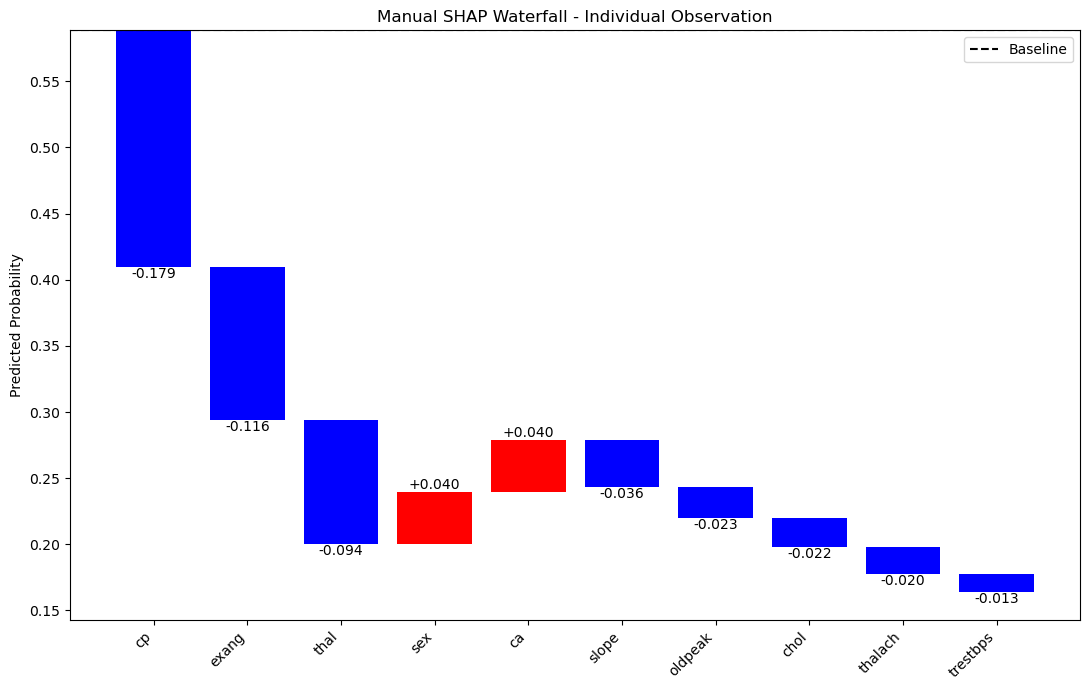

In [16]:

contributions = individual_values.copy()

sorted_indices = np.argsort(
    np.abs(contributions)
)[::-1]

top_features = sorted_indices[:10]

base_value = baseline_prediction
current_value = base_value

plt.figure(figsize=(11, 7))

for position, feature_index in enumerate(top_features):

    contribution = contributions[feature_index]

    next_value = current_value + contribution

    color = "red" if contribution > 0 else "blue"

    plt.bar(
        position,
        contribution,
        bottom=current_value,
        color=color
    )

    plt.text(
        position,
        next_value,
        f"{contribution:+.3f}",
        ha="center",
        va="bottom" if contribution >= 0 else "top"
    )

    current_value = next_value

plt.axhline(
    baseline_prediction,
    linestyle="--",
    color="black",
    label="Baseline"
)

plt.xticks(
    range(len(top_features)),
    np.array(feature_names)[top_features],
    rotation=45,
    ha="right"
)

plt.ylabel("Predicted Probability")
plt.title("Manual SHAP Waterfall - Individual Observation")
plt.legend()
plt.tight_layout()
plt.show()


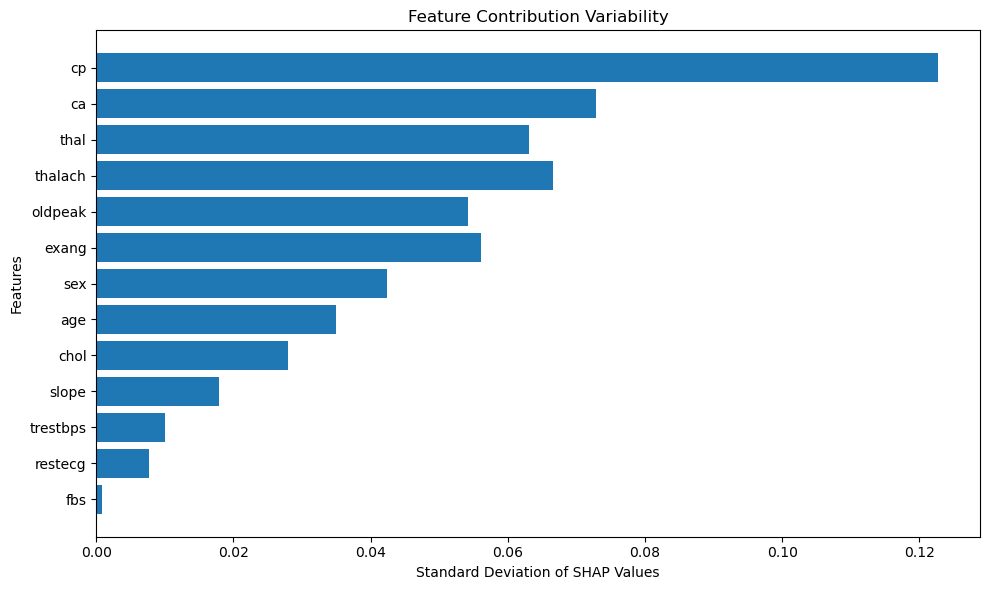

In [17]:


plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Contribution Std"]
)

plt.gca().invert_yaxis()

plt.xlabel("Standard Deviation of SHAP Values")
plt.ylabel("Features")
plt.title("Feature Contribution Variability")

plt.tight_layout()
plt.show()


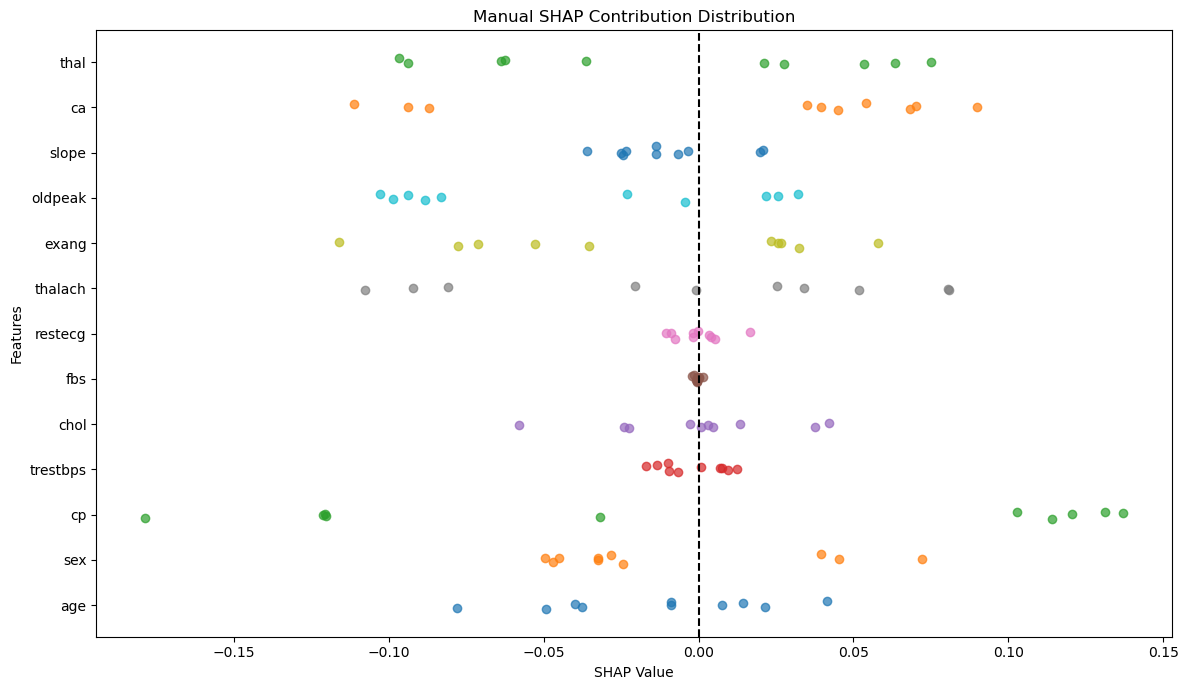

In [18]:

plt.figure(figsize=(12, 7))

for feature_index, feature in enumerate(feature_names):

    values = all_shap_values[:, feature_index]

    jitter = np.random.normal(
        0,
        0.06,
        size=len(values)
    )

    plt.scatter(
        values,
        np.full(len(values), feature_index) + jitter,
        alpha=0.7
    )

plt.axvline(
    0,
    color="black",
    linestyle="--"
)

plt.yticks(
    range(len(feature_names)),
    feature_names
)

plt.xlabel("SHAP Value")
plt.ylabel("Features")
plt.title("Manual SHAP Contribution Distribution")

plt.tight_layout()
plt.show()



In [19]:

positive_contributions = np.sum(
    all_shap_values > 0,
    axis=0
)

negative_contributions = np.sum(
    all_shap_values < 0,
    axis=0
)

contribution_analysis = pd.DataFrame({
    "Feature": feature_names,
    "Positive Contributions": positive_contributions,
    "Negative Contributions": negative_contributions,
    "Mean Absolute SHAP": mean_absolute_shap,
    "Contribution Std": shap_std
})

contribution_analysis = contribution_analysis.sort_values(
    "Mean Absolute SHAP",
    ascending=False
)

print("\nPOSITIVE AND NEGATIVE CONTRIBUTION ANALYSIS")
print(contribution_analysis.round(4).to_string(index=False))






POSITIVE AND NEGATIVE CONTRIBUTION ANALYSIS
 Feature  Positive Contributions  Negative Contributions  Mean Absolute SHAP  Contribution Std
      cp                       5                       5              0.1178            0.1227
      ca                       7                       3              0.0695            0.0728
    thal                       5                       5              0.0593            0.0631
 thalach                       5                       5              0.0574            0.0667
 oldpeak                       3                       7              0.0573            0.0542
   exang                       5                       5              0.0520            0.0561
     sex                       3                       7              0.0416            0.0424
     age                       4                       6              0.0307            0.0349
    chol                       6                       4              0.0209            0.0280
   sl

In [20]:
most_important_feature = importance_df.iloc[0]

most_variable_feature = importance_df.loc[
    importance_df["Contribution Std"].idxmax()
]

print("\nFINAL SHAP ANALYSIS")
print("----------------------------")

print(
    "Most Important Feature:",
    most_important_feature["Feature"]
)

print(
    "Mean Absolute SHAP:",
    round(most_important_feature["Mean Absolute SHAP"], 4)
)

print(
    "Most Variable Feature:",
    most_variable_feature["Feature"]
)

print(
    "Contribution Standard Deviation:",
    round(most_variable_feature["Contribution Std"], 4)
)

print(
    "\nBaseline Prediction:",
    round(baseline_prediction, 4)
)

print(
    "Explained Observations:",
    explain_count
)

print(
    "Permutations Per Observation:",
    number_of_permutations
)

print("\nManual SHAP analysis completed successfully.")


FINAL SHAP ANALYSIS
----------------------------
Most Important Feature: cp
Mean Absolute SHAP: 0.1178
Most Variable Feature: cp
Contribution Standard Deviation: 0.1227

Baseline Prediction: 0.5885
Explained Observations: 10
Permutations Per Observation: 30

Manual SHAP analysis completed successfully.
